# Teaching Computers to See : classification Cats vs Dogs avec un CNN

Objectif : construire, entraîner et évaluer un Convolutional Neural Network capable de distinguer des images de chats et de chiens, puis essayer d'améliorer ses performances.

# Import

In [10]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

## Début du code, récupération des images et taille
## Step 2 : Exploration du dataset

On définit les chemins vers les dossiers `train` et `validation`, puis on compte le nombre d'images de chaque classe (cats, dogs) dans chacun. On affiche aussi la taille de 20 images de chats pour vérifier si elles ont toutes les mêmes dimensions.

In [11]:
base_dir = "data/cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

for split, path in [("train", train_dir), ("validation", val_dir)]:
    for cls in ["cats", "dogs"]:
        folder = os.path.join(path, cls)
        print(f"{split}/{cls}: {len(os.listdir(folder))} images")

sample_dir = os.path.join(train_dir, "cats")
sizes = [Image.open(os.path.join(sample_dir, f)).size for f in os.listdir(sample_dir)[:20]]
print(sizes)

train/cats: 1000 images
train/dogs: 1000 images
validation/cats: 500 images
validation/dogs: 500 images
[(500, 374), (300, 280), (489, 499), (403, 499), (296, 200), (349, 343), (500, 386), (253, 399), (215, 174), (400, 374), (499, 350), (499, 332), (500, 374), (431, 410), (374, 500), (299, 356), (500, 374), (409, 308), (350, 261), (231, 270)]


### Analyse

Le dossier `train` contient 2000 images (1000 cats, 1000 dogs) et le dossier `validation` 1000 images (500 cats, 500 dogs). Les classes sont parfaitement équilibrées : l'accuracy sera donc une métrique fiable, et aucune pondération des classes n'est nécessaire.

Les images sont en couleur (3 canaux RGB), mais leurs dimensions varient d'une image à l'autre. Un CNN demande une entrée de taille fixe, donc toutes les images seront redimensionnées en 150×150 au chargement.

### Visualisation de quelques images

On affiche 4 images tirées au hasard pour chaque classe (cats sur la première ligne, dogs sur la seconde), avec leurs dimensions en titre, pour se faire une idée concrète des données.

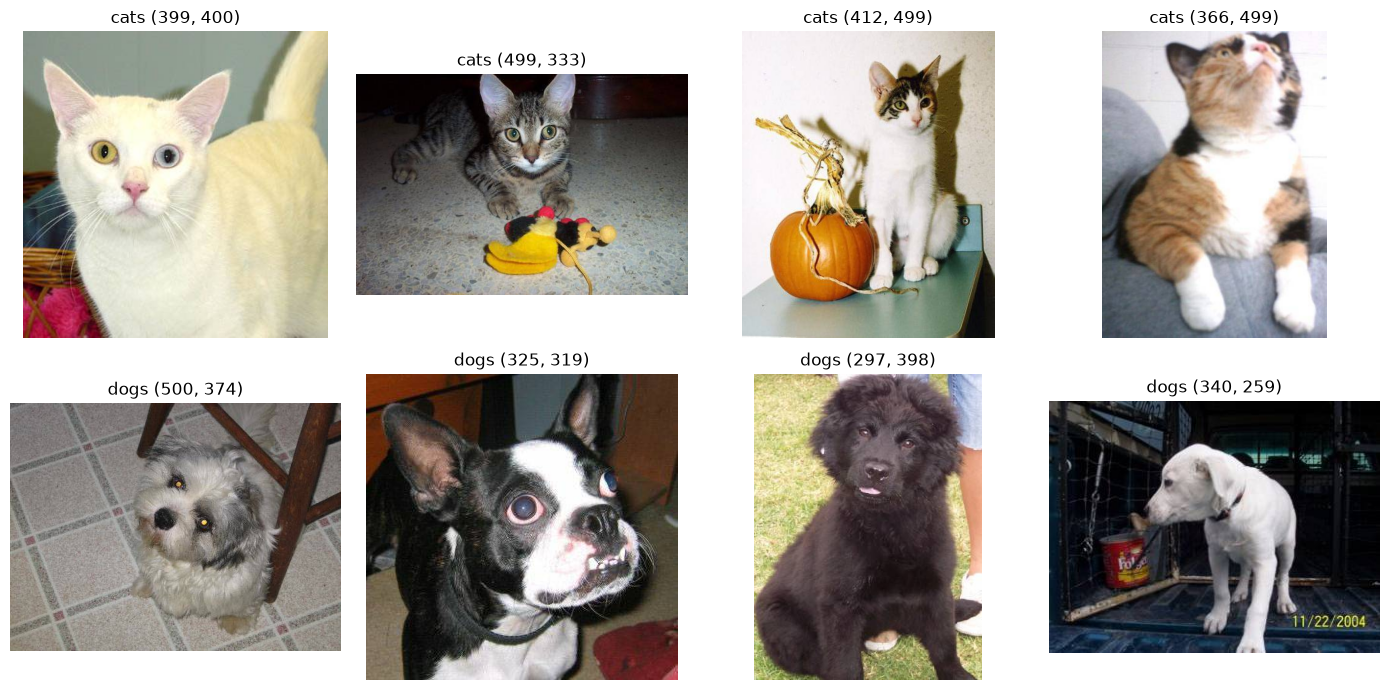

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls in enumerate(["cats", "dogs"]):
    folder = os.path.join(train_dir, cls)
    for ax, fname in zip(axes[row], random.sample(os.listdir(folder), 4)):
        img = Image.open(os.path.join(folder, fname))
        ax.imshow(img)
        ax.set_title(f"{cls} {img.size}")
        ax.axis("off")
plt.tight_layout()
plt.show()

On observe une grande variété dans les images : cadrages différents, arrière-plans plus ou moins encombrés, animaux partiellement visibles ou accompagnés d'humains, éclairages variables. Les dimensions changent aussi d'une image à l'autre, ce qui confirme la nécessité du redimensionnement. La tâche n'est donc pas triviale : le modèle devra apprendre des caractéristiques propres à l'animal, et non à l'arrière-plan.

### Split 80/20 et chargement des données

On charge les images avec `image_dataset_from_directory`, qui associe automatiquement chaque image à sa classe d'après le nom de son dossier.

- **Redimensionnement en 150×150** : assez grand pour garder les détails utiles (oreilles, museau, pelage), assez petit pour que l'entraînement reste raisonnable.
- **Split 80/20 du dossier `train`** : 80 % pour l'entraînement (1600 images) et 20 % pour le test (400 images). Le test set n'est utilisé qu'à l'évaluation finale, ce qui donne une mesure honnête des

In [12]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 100

train_ds, test_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

print(train_ds.class_names)
for images, labels in train_ds.take(1):
    print(images.shape, labels.shape)

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Using 400 files for validation.
Found 1000 files belonging to 2 classes.
['cats', 'dogs']
(100, 150, 150, 3) (100, 1)


Keras affiche "Using 400 files for validation" pour le deuxième sous-ensemble du split : dans notre cas, ces 400 images constituent bien le **test set**, la validation étant le dossier séparé de 1000 images.

Les classes sont détectées dans l'ordre alphabétique : `cats` = 0 et `dogs` = 1. Un batch a la forme `(100, 150, 150, 3)` : 100 images de 150×150 pixels sur 3 canaux RGB. Les labels ont la forme `(100, 1)`, une valeur binaire par image. L'input shape du modèle sera donc `(150, 150, 3)`.